In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

<class 'ModuleNotFoundError'>: No module named 'seaborn'

In [40]:
data = load_diabetes()

In [41]:
df = pd.DataFrame(data.data, columns=data.feature_names)
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [42]:
X = df[["bmi"]]
y = data.target

In [43]:
X_train, X_test, y_train,y_test = train_test_split(X,y,random_state=42,test_size = 0.2)

In [44]:
degree = [1,2,3,5,10,15]

result = []

In [45]:
for d in degree:
    model = make_pipeline(PolynomialFeatures(),LinearRegression())
    model.fit(X_train,y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)
    rmse = np.sqrt(test_mse)
    r2 = r2_score(y_test,test_pred)

    result.append([d, train_mse, test_mse, rmse, r2])

In [46]:
df = pd.DataFrame(results, columns=["Degree", "Train MSE","Test MSE","RMSE","R2"])

In [47]:
print(df)

   Degree    Train MSE      Test MSE        RMSE        R2
0       1  3854.112652   4061.825928   63.732456  0.233350
1       2  3849.333133   4085.025481   63.914204  0.228972
2       3  3848.447238   4064.443384   63.752987  0.232856
3       5  3823.763813   4085.845567   63.920619  0.228817
4      10  3724.612687   4315.533060   65.692717  0.185464
5      15  3708.122534  30391.328894  174.331090 -4.736213


Text(0.5, 1.0, 'Bias-Variance Trade-off')

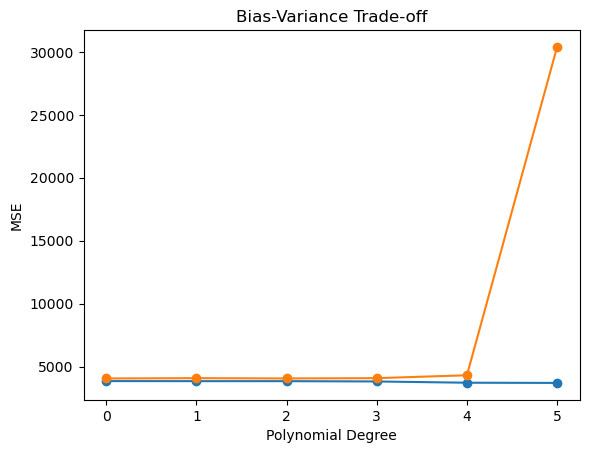

In [48]:
plt.plot(df["Train MSE"], marker="o")
plt.plot(df["Test MSE"], marker="o")
plt.xlabel("Polynomial Degree")
plt.ylabel("MSE")
plt.title("Bias-Variance Trade-off")